## Analyzing a player's dismissals patterns, strengths and weaknesses

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import numpy as np

In [2]:
# Load the comprehensive player data CSV file generated from JSON files
player_dismissal_file = 'data/all_players_batting_stats.csv'
data = pd.read_csv(player_dismissal_file)

# Display the first few rows of the DataFrame
print(data.head())

  Player Name       Team     Bowler Type       Span  Dis  bwd  caught  st  \
0   DA Warner  Australia   left-arm-pace  2002-2024   24    2      18   0   
1   DA Warner  Australia  right-arm-spin  2002-2024   30    7      13   1   
2   DA Warner  Australia  right-arm-pace  2002-2024   89   15      63   0   
3   DA Warner  Australia   left-arm-spin  2002-2024   12    1       8   0   
4   DA Warner  Australia         unknown  2002-2024    0    0       0   0   

   lbw  hw  ro  oth  dot_balls    Ave    BF  Runs  
0    3   0   1    0        573  36.00   981   864  
1    4   0   2    3        690  39.43  1369  1183  
2    4   0   4    3       2128  45.12  3985  4016  
3    1   0   1    1        383  63.25   835   759  
4    0   0   0    0         43   0.00   104   110  


In [3]:
# Display the summary of the DataFrame
print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7678 entries, 0 to 7677
Data columns (total 16 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Player Name  7678 non-null   object 
 1   Team         7678 non-null   object 
 2   Bowler Type  7678 non-null   object 
 3   Span         7678 non-null   object 
 4   Dis          7678 non-null   int64  
 5   bwd          7678 non-null   int64  
 6   caught       7678 non-null   int64  
 7   st           7678 non-null   int64  
 8   lbw          7678 non-null   int64  
 9   hw           7678 non-null   int64  
 10  ro           7678 non-null   int64  
 11  oth          7678 non-null   int64  
 12  dot_balls    7678 non-null   int64  
 13  Ave          7678 non-null   float64
 14  BF           7678 non-null   int64  
 15  Runs         7678 non-null   int64  
dtypes: float64(1), int64(11), object(4)
memory usage: 959.9+ KB
None


## Extracting Player's Statistics

In [4]:
# Define the player name dynamically
player_name = "V Kohli"  # Dynamic input for any player

# Check if the player name exists in the DataFrame
if player_name in data['Player Name'].values:
    # Filter the DataFrame to get all the stats for the selected player
    player_data = data[data['Player Name'] == player_name]

    # Display the data for the player
    print(f"Data for {player_name}:")
    print(player_data)
else:
    # Output an error message if the player is not found
    print(f"Error: Player '{player_name}' not found in the DataFrame.")
    # Raise an exception to stop further execution
    raise ValueError(f"Player '{player_name}' not found in the DataFrame.")


Data for V Kohli:
    Player Name   Team     Bowler Type       Span  Dis  bwd  caught  st  lbw  \
699     V Kohli  India  right-arm-spin  2002-2024   51   10      24   3    7   
700     V Kohli  India   left-arm-spin  2002-2024   25    5      12   2    2   
701     V Kohli  India   left-arm-pace  2002-2024   36    5      27   0    2   
702     V Kohli  India  right-arm-pace  2002-2024  132   13      99   0    7   
703     V Kohli  India         unknown  2002-2024    2    1       0   0    1   

     hw  ro  oth  dot_balls    Ave    BF  Runs  
699   1   3    3       1373  66.10  3602  3371  
700   0   1    3        750  63.32  1800  1583  
701   0   2    0        874  45.78  1732  1648  
702   0  13    0       3906  54.09  7843  7140  
703   0   0    0         73  82.00   176   164  


# Analysis of Dismissal Types for the player

In [5]:
#Drop rows where 'Bowler Type' is 'mixture/unknown'
player_data_filtered = player_data[player_data['Bowler Type'] != 'unknown']

In [6]:
# List of dismissal types
dismissal_types = ['bwd', 'caught', 'st', 'lbw', 'hw', 'ro']

# Aggregate dismissal counts
dismissal_counts = player_data[dismissal_types].sum()

# Display the aggregated dismissal counts
print(dismissal_counts)

bwd        34
caught    162
st          5
lbw        19
hw          1
ro         19
dtype: int64


A pie chart visualization will display the different ways the player has been dismissed, showing the proportion of each dismissal type. This chart provides a clear and concise view of the frequency of each dismissal type

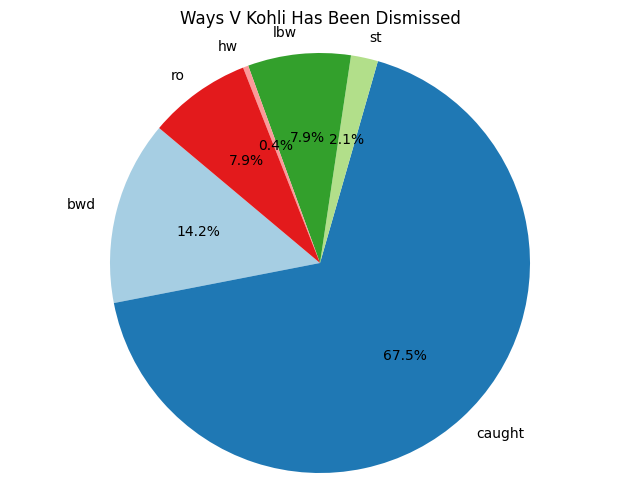

In [7]:
# pie chart
plt.figure(figsize=(8, 6))
plt.pie(dismissal_counts, labels=dismissal_counts.index, autopct='%1.1f%%', colors=plt.cm.Paired(range(len(dismissal_counts))), startangle=140)
plt.title(f'Ways {player_name} Has Been Dismissed')
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()

- We can see that Kohli has been dismissed by caught the most number of times. According to my observation Kohli has been caught behind or at slips when the ball is pitched at off stump and moving away from him.
- He tends to chip it to point and covers as well when he is trying to drive or cutt the ball.
- His running between the wickets is really good hence that ratio of runouts is less in the visualization.
- He is also very good in using his feet against spinner hence the stumps way of getting out is also less.


Dismissals of the player against diffrent bowler types

In [8]:
# Aggregate dismissal counts by bowler type
dismissals_by_bowler_type = player_data_filtered.groupby('Bowler Type')[dismissal_types].sum().reset_index()

# Display the aggregated dismissal counts
print(dismissals_by_bowler_type)

      Bowler Type  bwd  caught  st  lbw  hw  ro
0   left-arm-pace    5      27   0    2   0   2
1   left-arm-spin    5      12   2    2   0   1
2  right-arm-pace   13      99   0    7   0  13
3  right-arm-spin   10      24   3    7   1   3


In [9]:
# dismissals_by_bowler_type.head
dismissals_by_bowler_type.columns

Index(['Bowler Type', 'bwd', 'caught', 'st', 'lbw', 'hw', 'ro'], dtype='object')

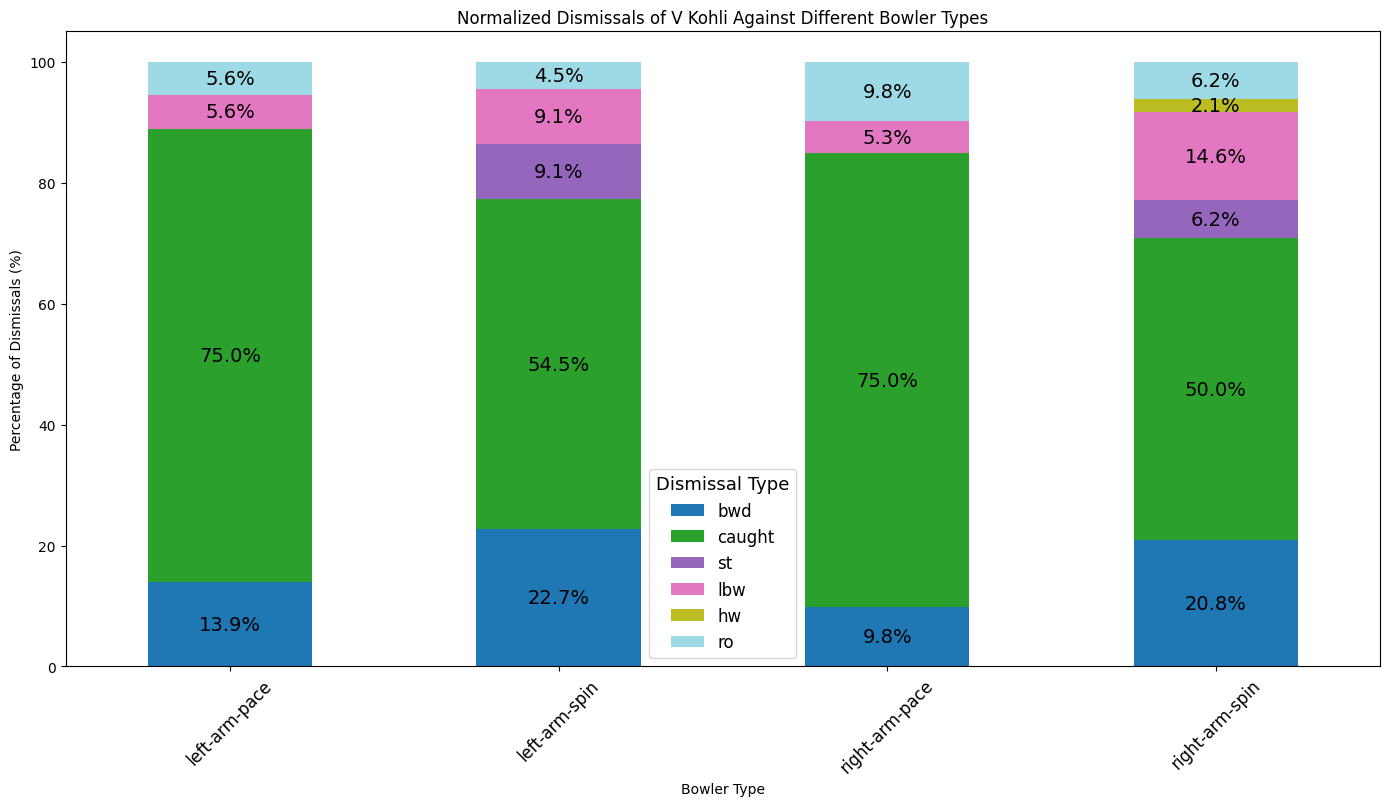

In [10]:
# Calculate total dismissals for each bowler type
dismissals_by_bowler_type['Total Dismissals'] = dismissals_by_bowler_type[dismissal_types].sum(axis=1)

# Normalize each dismissal type by the total dismissals for that bowler type
for dismissal_type in dismissal_types:
    dismissals_by_bowler_type[dismissal_type] = (dismissals_by_bowler_type[dismissal_type] / dismissals_by_bowler_type['Total Dismissals']) * 100

# Drop the total dismissals column as it's no longer needed
dismissals_by_bowler_type.drop(columns='Total Dismissals', inplace=True)

# Plot the normalized stacked bar plot
ax = dismissals_by_bowler_type.set_index('Bowler Type')[dismissal_types].plot(kind='bar', stacked=True, figsize=(14, 8), colormap='tab20')

# Add labels and title
plt.title(f'Normalized Dismissals of {player_name} Against Different Bowler Types')
plt.xlabel('Bowler Type')
plt.ylabel('Percentage of Dismissals (%)')
plt.xticks(rotation=45)
plt.tight_layout()

# Add percentage labels within the bars
for i in range(dismissals_by_bowler_type.shape[0]):
    bottom = 0
    for j, col in enumerate(dismissal_types):
        value = dismissals_by_bowler_type.iloc[i][col]
        if value > 0:
            ax.text(i, bottom + value / 2, f'{value:.1f}%', ha='center', va='center', color='black', fontsize=14)
        bottom += value

ax.legend(title='Dismissal Type', title_fontsize=13, fontsize=12)
ax.tick_params(axis='x', labelsize=12)

# Show the plot
plt.show()


1. Left-Arm Pace

Kohli is cautious early on against left-arm pacers, focusing on getting singles. He often uses a slightly closed stance to guard against balls coming in but this can make him vulnerable to deliveries that move away.

Caught Behind: He sometimes pushes at balls outside off-stump, especially early in his innings, leading to edges to the slips or wicketkeeper.

LBW/Bowled: When the ball swings in, he can be trapped in front as he tries to flick across the line.

Left-arm pacers target his off-stump early when he’s trying to drive before settling.

He is confident in cover drives which is his favourite shot so early on when the ball is new, he gets caught in slip while driving because the swing factor comes in

2. Left-Arm Spin

Kohli uses his feet well, advancing to convert good-length deliveries into driveable balls. He also sweeps to control spin and manipulate the field.

Caught Close: On turning pitches, he can edge balls to slip or short leg when playing with hard hands.

LBW: If the ball drifts in and skids, he might miss it while trying to play across.

Kohli prefers to rotate strike but gets cautious when facing turn and bounce.

3. Right-Arm Pace

Kohli excels against right-arm pace, using a slightly open stance to drive straight and cover drives with a compact technique. He’s quick to adjust to bouncers, often playing hooks or uppercuts if the field allows.

Caught Behind: Pushing at outswingers early in his innings can lead to edges.

Caught: One observation is that, when the ball is pitched at short to good length he gets uncomfortable with the bounce early on. When he tries to hit it hard, it usually mistimes and gets caught within the range of the field circle

LBW/Bowled: Occasionally, he falls across when trying to flick, making him vulnerable to straight, full deliveries.

His eagerness to dominate pace can sometimes lead to early edges when the ball moves away from him.

4. Right-Arm Spin (Off-Spin and Leg-Spin)

Kohli uses his wrists to turn off-spin deliveries into the leg side. Against leg-spin, he uses quick footwork, often advancing to hit lofted shots or drive.

Caught: Mistimed lofted shots when he tries to dominate, especially against leg-spin.

Confident against spin, Kohli sometimes risks his wicket when he rushes to attack.

Normalizing the dismissals by each bowler against the player with the balls faced

In [11]:
# Aggregate total dismissals and balls faced by bowler type
dismissals_by_bowler_type = player_data_filtered.groupby('Bowler Type')['Dis'].sum().reset_index()
balls_faced_by_bowler_type = player_data_filtered.groupby('Bowler Type')['BF'].sum().reset_index()

# Merge the two DataFrames
dismissals_balls = pd.merge(dismissals_by_bowler_type, balls_faced_by_bowler_type, on='Bowler Type')

# Calculate dismissal rate per ball faced
dismissals_balls['Dismissal Rate'] = dismissals_balls['Dis'] / dismissals_balls['BF']

# Display the normalized dismissal rates
print(dismissals_balls)

      Bowler Type  Dis    BF  Dismissal Rate
0   left-arm-pace   36  1732        0.020785
1   left-arm-spin   25  1800        0.013889
2  right-arm-pace  132  7843        0.016830
3  right-arm-spin   51  3602        0.014159


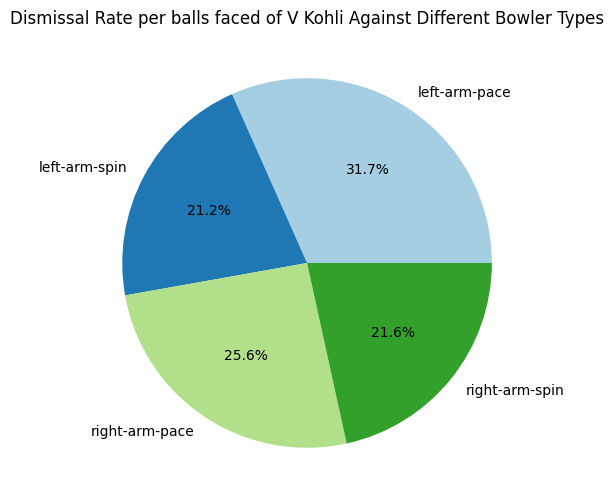

In [12]:
# Prepare data for pie plot
pie_data = dismissals_balls.set_index('Bowler Type')['Dismissal Rate']

# Plot a pie chart
plt.figure(figsize=(8, 6))
plt.pie(pie_data, labels=pie_data.index, autopct='%1.1f%%', colors=plt.cm.Paired(range(len(pie_data))))
plt.title(f'Dismissal Rate per balls faced of {player_name} Against Different Bowler Types')
plt.show()

Even though he has played less balls from the left-arm-pace category, the dissmisaal rate is the most.

This means that he is most likely to get out from this category of bowler.

Left Arm Pacers (Over the Wicket):
- The Angle of the ball is from left to right. If the ball is new and swinging:
    1. Away: He ends up nicking which is usually carried to the keeper or slip cordon.
    2. In: The chance of LBW and getting bowled increases.

# Analysis of Runs Scored for the player

Extracting the Runs data of selected player

In [13]:
# Aggregate total runs scored against each bowler type
runs_by_bowler_type = player_data_filtered.groupby('Bowler Type')['Runs'].sum().reset_index()

# Display the aggregated data
print(runs_by_bowler_type)

      Bowler Type  Runs
0   left-arm-pace  1648
1   left-arm-spin  1583
2  right-arm-pace  7140
3  right-arm-spin  3371


Bar plot of Runs Scored by the player against each Bowler Type

<Figure size 1200x600 with 0 Axes>

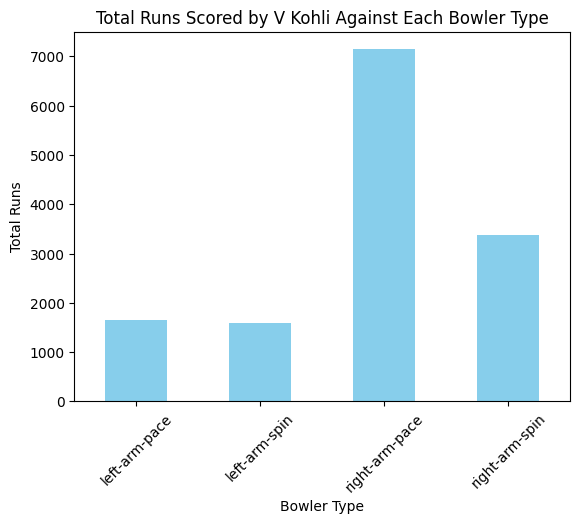

In [14]:
plt.figure(figsize=(12, 6))
runs_by_bowler_type.plot(kind='bar', x='Bowler Type', y='Runs', color='skyblue', legend=False)
plt.title(f'Total Runs Scored by {player_name} Against Each Bowler Type')
plt.xlabel('Bowler Type')
plt.ylabel('Total Runs')
plt.xticks(rotation=45)
plt.show()

This analysis does not tell us much apart from the fact that he has played right-arm-pace significantly more than any other type of bowler throughout his career hence he has scored the most runs against this category of bowler

In this analyzation of runs scored by Kohli against different categories of bowlers, we can see that he has scored the most runs against right-arm-pace but this does not tell us much as the balls faced is also the most in this category.

Plot both runs scored and balls faced by the player for each bowler type

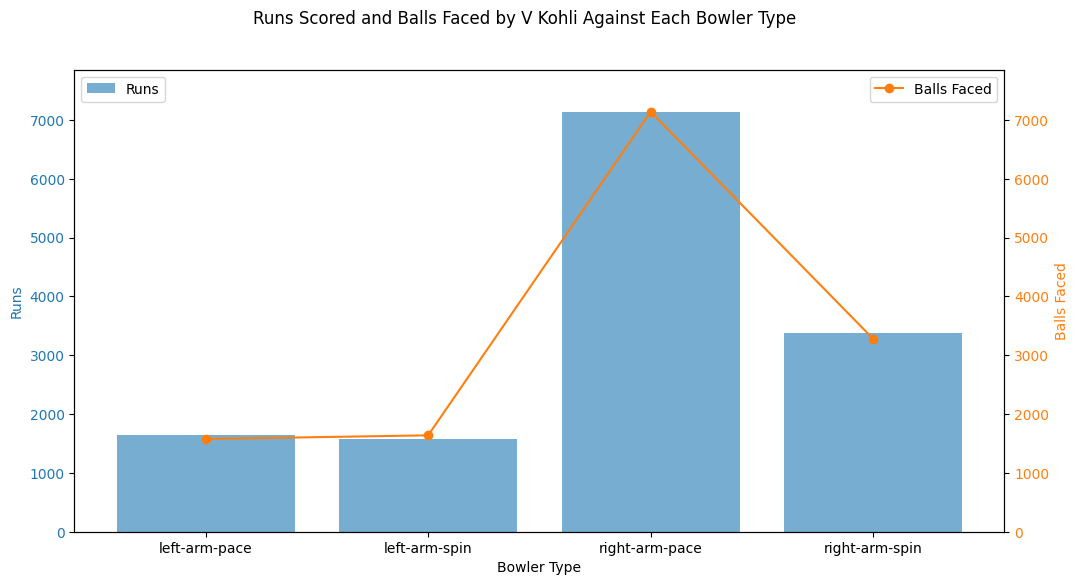

In [15]:
import matplotlib.pyplot as plt

# Aggregate total runs and balls faced against each bowler type
runs_balls_by_bowler_type = player_data_filtered.groupby('Bowler Type').agg({'Runs': 'sum', 'BF': 'sum'}).reset_index()

# Determine the common limit based on the maximum value of runs and balls faced
max_runs = runs_balls_by_bowler_type['Runs'].max()
max_balls_faced = runs_balls_by_bowler_type['BF'].max()

# Calculate scaling factor to normalize the secondary axis to the primary axis range
scaling_factor = max_runs / max_balls_faced

# Create a dual-axis plot
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot Runs on the primary y-axis
color = 'tab:blue'
ax1.set_xlabel('Bowler Type')
ax1.set_ylabel('Runs', color=color)
ax1.bar(runs_balls_by_bowler_type['Bowler Type'], runs_balls_by_bowler_type['Runs'], color=color, alpha=0.6, label='Runs')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0, max_runs * 1.1)  # Extend limit a bit for better visibility

# Create a secondary y-axis for Balls Faced
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Balls Faced', color=color)
# Normalize the Balls Faced data to align with the Runs data range
ax2.plot(runs_balls_by_bowler_type['Bowler Type'], runs_balls_by_bowler_type['BF'] * scaling_factor, color=color, marker='o', label='Balls Faced')
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylim(0, max_runs * 1.1)  # Use the same range as the primary y-axis

# Add titles and legends
fig.suptitle(f'Runs Scored and Balls Faced by {player_name} Against Each Bowler Type')
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')

# Rotate x-axis labels for better readability
plt.xticks(rotation=45)

plt.show()


This shows us that the scoring rate of kohli is consistent against each type of bowler. This only shows us that in terms of runs scored, Kohli does not let any bowler dominate him as he scores consistently.

The visualization shows that the number of runs scored against the number of balls faced is approximately the same showing a strike rate of 100 

The deviation/variation of left arm spin from the other bowling types hints towards a slight weakness or a defensive approach against this type of bowling compared to the rest of the bowling types

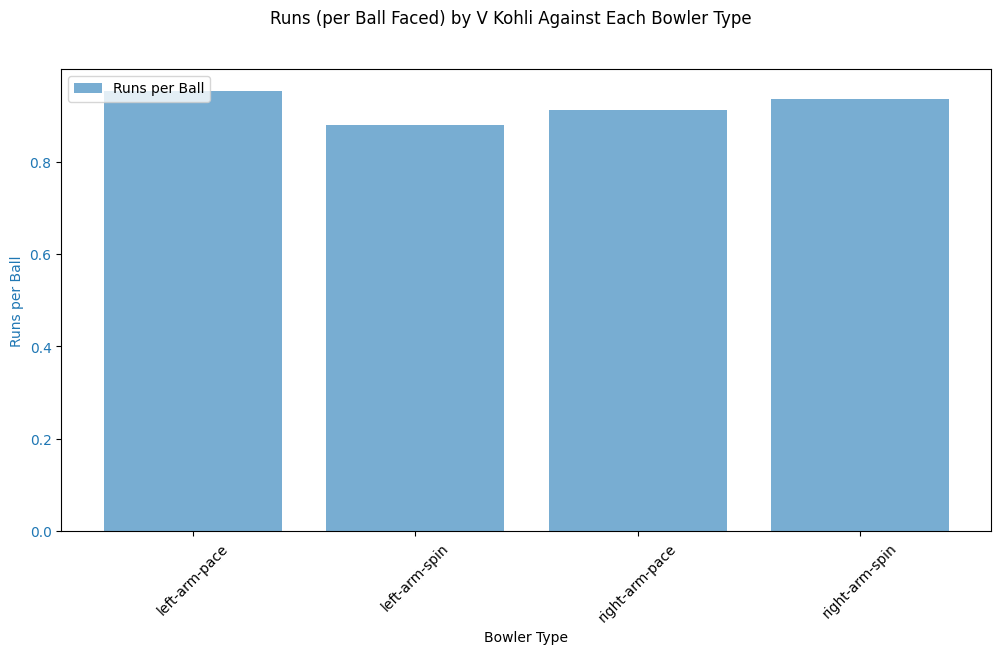

In [16]:
# Normalize runs against balls faced by calculating runs per ball
runs_balls_by_bowler_type['Runs per Ball'] = runs_balls_by_bowler_type['Runs'] / runs_balls_by_bowler_type['BF']

# Plot the normalized data
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot normalized runs per ball
color = 'tab:blue'
ax1.set_xlabel('Bowler Type')
ax1.set_ylabel('Runs per Ball', color=color)
ax1.bar(runs_balls_by_bowler_type['Bowler Type'], runs_balls_by_bowler_type['Runs per Ball'], color=color, alpha=0.6, label='Runs per Ball')
ax1.tick_params(axis='y', labelcolor=color)

# Add titles and legend
fig.suptitle(f'Runs (per Ball Faced) by {player_name} Against Each Bowler Type')
ax1.legend(loc='upper left')

# Rotate x-axis labels for better readability
plt.xticks(rotation=45)

plt.show()

This shows that Kohli’s scoring rate is good against all types of bowler generally. Relatively low against left-arm-spin.

What can we deduce from this?

As we can see this visualize corroborates with the above one"
- If we calculate the strike rate using runs per ball and balls faced, we can see that this difference is quite a lot if we assume it for a long innings 

for e.g 82 SR vs roughly 100 SR 

Plot of average runs scored by the player against each bowler type

In [17]:
# Average runs scored against each bowler type
avg_runs_by_bowler_type = player_data_filtered.groupby('Bowler Type')['Ave'].sum().reset_index()

# Display the aggregated data
print(avg_runs_by_bowler_type)

      Bowler Type    Ave
0   left-arm-pace  45.78
1   left-arm-spin  63.32
2  right-arm-pace  54.09
3  right-arm-spin  66.10


Bar plot of Average Runs Scored by the player against each Bowler Type

<Figure size 1200x600 with 0 Axes>

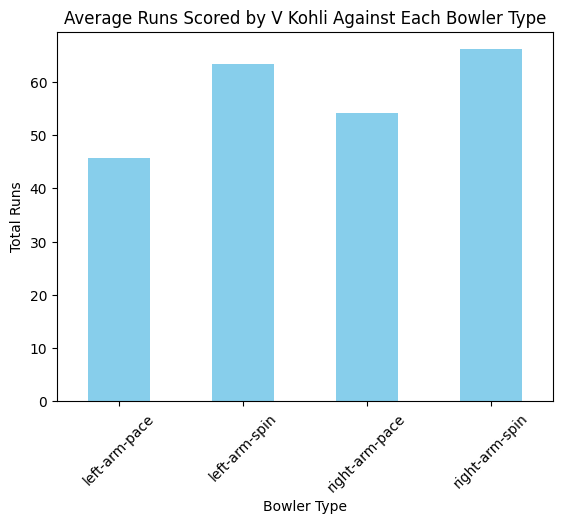

In [18]:
plt.figure(figsize=(12, 6))
avg_runs_by_bowler_type.plot(kind='bar', x='Bowler Type', y='Ave', color='skyblue', legend=False)
plt.title(f'Average Runs Scored by {player_name} Against Each Bowler Type')
plt.xlabel('Bowler Type')
plt.ylabel('Total Runs')
plt.xticks(rotation=45)
plt.show()

- This is a better visualization to understand his career average against each bowling type
- Runs per dismissal is the lowest for left arm pace showing his direct weakness/ defensive approach against this category of bowling

- We can interestingly observe the average against left arm spin is quite higher which we would not have expected 
based on the previous graphs

- This could be due to a few reaons
- Sample Size of balls faced against left arm spinners is quite low 
- Spin friendly pitches only in Subcontinent ( Ban and Sri) 


Pie plot of avg runs for % visualization

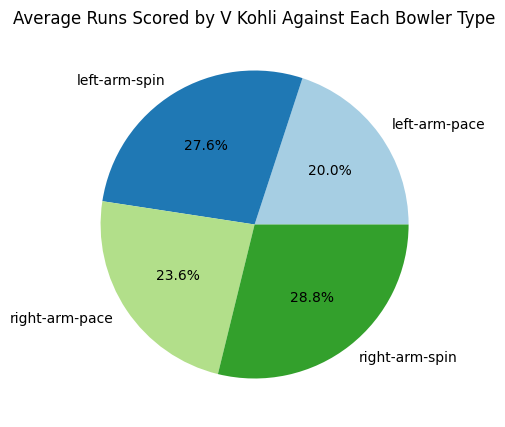

In [19]:
plt.figure(figsize=(5, 5))
avg_runs_by_bowler_type.set_index('Bowler Type')['Ave'].plot(kind='pie', autopct='%1.1f%%', colors=plt.cm.Paired(range(len(avg_runs_by_bowler_type))), legend=False)
plt.title(f'Average Runs Scored by {player_name} Against Each Bowler Type')
plt.ylabel('')
plt.show()

Lowest Average Against Left-Arm Pace: His batting average against left-arm pace bowlers is the lowest.This indicates that Kohli is dismissed more frequently by left-arm pace bowlers compared to other types of bowlers, suggesting a relative vulnerability.

Comfort Against Right-Arm Spin: Kohli has fewer dismissals per runs scored against right-arm spin bowlers, indicating a higher batting average and showing that he is more comfortable playing against this type of bowling.